## 선형회귀모델(Linear Regression Model)

In [1]:
"""
<특징>
 - 과거에 가장 널리 사용되었던 대표적인 회귀모델
 - 비교적 간단하며, 성능이 뛰어나기 때문에 회귀모델 수행 시 가장 처음에 비교대상 모델로 좋음
 - 선형회귀모델은 하이퍼파라메터 튜닝 속성(변수)이 없음
 -> 튜닝을 하려면 : 독립변수의 선형 분포에 따라 특성을 늘리는(추가하는) 처리를 하면 됨.

<선형회귀모델(LinearRegression) 종류>
    - 선형회귀모델(직선) : 독립변수의 특성(컬럼)이 한개인 경우 사용 : y = aX + b
    - 다항회귀모델(곡선) : 독립변수의 특성(컬럼)이 두개인 경우 사용 : y = aX^2 + bX + c
    - 다중회귀모델(포물선) : 독립변수의 특성(컬럼)이 여러개인 경우 사용 y = ax1 + bx2 + cx3 + dx4...


<사용 라이브러리>
 - 패키지 : sklearn.linear_model
 - 모델(클래스) : LinearRegression
               : 선형/다항/다중회귀 알고리즘(산술식)을 모두 포함하고 있는 모델
 - 모델이 자체적으로 독립변수의 특성 갯수를 확인해서
   직선, 곡선, 포물선 알고리즘(산술식)을 알아서 선택 처리합니다.
"""


'\n<특징>\n - 과거에 가장 널리 사용되었던 대표적인 회귀모델\n - 비교적 간단하며, 성능이 뛰어나기 때문에 회귀모델 수행 시 가장 처음에 비교대상 모델로 좋음\n - 선형회귀모델은 하이퍼파라메터 튜닝 속성(변수)이 없음\n -> 튜닝을 하려면 : 독립변수의 선형 분포에 따라 특성을 늘리는(추가하는) 처리를 하면 됨.\n\n<선형회귀모델(LinearRegression) 종류>\n    - 선형회귀모델(직선) : 독립변수의 특성(컬럼)이 한개인 경우 사용 : y = aX + b\n    - 다항회귀모델(곡선) : 독립변수의 특성(컬럼)이 두개인 경우 사용 : y = aX^2 + bX + c\n    - 다중회귀모델(포물선) : 독립변수의 특성(컬럼)이 여러개인 경우 사용 y = ax1 + bx2 + cx3 + dx4...\n\n\n<사용 라이브러리>\n - 패키지 : sklearn.linear_model\n - 모델(클래스) : LinearRegression\n               : 선형/다항/다중회귀 알고리즘(산술식)을 모두 포함하고 있는 모델\n - 모델이 자체적으로 독립변수의 특성 갯수를 확인해서\n   직선, 곡선, 포물선 알고리즘(산술식)을 알아서 선택 처리합니다.\n'

In [2]:
"""
<전체 분석 순서>
데이터 수집 > 데이터 전처리 > 가공(데이터 스케일링, 특성 추가, 훈련:검증:테스트 분류 등등)

> 모델 클래스 생성 > 훈련시키기(fit) > 정확도(score)(회귀: 결정계수라고 칭함) > 과적합 여부 해석
> 하이퍼파라메터 튜닝(튜닝이 필요한 경우 수행) > 예측(predict) > 평가(오차: 회귀, 지표:분류)

** 위의 과정을 다른 여러 모델로도 적용
최종 모델 선정을 위한 모델 간 비교> 최종 모델 선정 > 파일로 저장 > 서비스 영역에 배포(전달)
"""

'\n<전체 분석 순서>\n데이터 수집 > 데이터 전처리 > 가공(데이터 스케일링, 특성 추가, 훈련:검증:테스트 분류 등등)\n\n> 모델 클래스 생성 > 훈련시키기(fit) > 정확도(score)(회귀: 결정계수라고 칭함) > 과적합 여부 해석\n> 하이퍼파라메터 튜닝(튜닝이 필요한 경우 수행) > 예측(predict) > 평가(오차: 회귀, 지표:분류)\n\n** 위의 과정을 다른 여러 모델로도 적용\n최종 모델 선정을 위한 모델 간 비교> 최종 모델 선정 > 파일로 저장 > 서비스 영역에 배포(전달)\n'

### 사용할 라이브러리 정의

In [3]:
### 숫자 데이터 처리용
import numpy as np

### 훈련:검증:테스트 데이터 분리용 함수
from sklearn.model_selection import train_test_split

#### 데이터 정의

In [4]:
### 농어의 길이
perch_length= np.array(
    [8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0,
     21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5,
     22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5,
     27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0,
     36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0,
     40.0, 42.0, 43.0, 43.0, 43.5, 44.0]
     )


### 농어 무게
perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
     110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
     130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
     197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
     514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
     820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
     1000.0, 1000.0]
     )

# np.array : 그냥 리스트라 보면 됨.

print(perch_length.shape, perch_weight.shape)

(56,) (56,)


### 독립변수와 종속변수 정의하기

In [5]:
"""
* 주제 : 길이를 이용하여 무게 예측하기
- 독립변수(X) : perch_length
- 종속변수(y) : perch_weight
"""

'\n* 주제 : 길이를 이용하여 무게 예측하기\n- 독립변수(X) : perch_length\n- 종속변수(y) : perch_weight\n'

### 데이터 분리하기

In [6]:
### 훈련 : 테스트 = 75% : 25% 분리하기
# 훈련데이터의 변수명 : train_input, train_target
# 테스트 데이터 변수명 : test_input, test_target

# random_state=42 빼먹음. 한쪽에 편향되게 데이터 쏠리는 거 방지
train_input, test_input, train_target, test_target = train_test_split(perch_length, perch_weight, test_size=0.25, random_state=42)

print(train_input.shape, train_target.shape)
print(test_input.shape, test_target.shape)


(42,) (42,)
(14,) (14,)


### 훈련을 시키기 위한 독립변수의 차원 확인

In [7]:
### 훈련을 위한 독립변수의 차원은 2차원, 종속변수는 1차원
# 독립변수를 2차원으로 수정하기
# reshape(행, 열) : 넘파이(numpy) 라이브러리에서 제공되는 함수 까먹었음!
train_input = train_input.reshape(-1, 1)
test_input = test_input.reshape(-1, 1)
### 차원 확인하기
print(train_input.shape, train_target.shape)
print(test_input.shape, test_target.shape)



(42, 1) (42,)
(14, 1) (14,)


### 훈련(학습)시키기

In [8]:
### 1. 훈련에 사용할 모델 클래스 생성시키기
from sklearn.linear_model import LinearRegression

lnr = LinearRegression()
lnr

### 2. 훈련 시키기
lnr.fit(train_input, train_target)

### 3. 훈련 및 테스트의 정확도(결정계수) 확인하기
lnr.score(train_input, train_target)
lnr.score(test_input, test_target)

train_score = lnr.score(train_input, train_target)
test_score = lnr.score(test_input, test_target)
train_score - test_score

print(train_score, test_score, train_score - test_score)
### <과적합 해석> 
### 과대적합. 훈련수치와 테스트 수치 0.115 이상 차이


### 4. 예측하기 (테스트 데이터로 예측) 
### predict(여기는 독립변수만 넣어야함. 문제를 준다는 개념)
### 훈련 및 테스트 데이터로 예측을 하는데 여기서는 테스트 데이터로만 진행함
test_pred = lnr.predict(test_input)

### 5. 오차 확인하기 파트 까먹음. 실제 정답(종속변수)과 예측 결과값의 오차를 확인하는 과정임.
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score ### 까먹음.
#mae(평균절대오차, 0에 가까울수록 좋음)
mae = mean_absolute_error(test_target, test_pred)
print(mae)
#mse(평균제곱오차, 0에 가까울수록 좋음)
mse = mean_squared_error(test_target, test_pred)
print(mse)
#r2(결정계수 정확도, 1에 가까울수록 좋음.)
r2 = r2_score(test_target, test_pred)
print(r2)

### 6. 임의값(50)으로 예측해보기
pred_50 = lnr.predict([[50]])
print(pred_50)

### KNN의 경우 1033.333
### LinearReggression의 경우 1241.838


0.9398463339976041 0.824750312331356 0.1150960216662481
94.46122937985578
17590.26597788917
0.824750312331356
[1241.83860323]


In [9]:
# 기본 시각화 라이브러리
import matplotlib.pyplot as plt

# 통계적 시각화 라이브러리(보통 기본 시각화보다 향상된 라이브러리라고 생각하면 됨)
import seaborn as sns

# 시각화 시 그래프의 너비/높이 기본 설정하기(단위=인치)
plt.rcParams["figure.figsize"] = (12, 5)

# 시각화시 한글 깨짐 처리를 위한 폰트 지정(Window OS 기준, Mac OS나 Linux는 그에 맞게)
plt.rcParams['font.family'] = 'Malgun Gothic'

# 시각화시 마이너스(-) 기호 깨짐 방지 처리
plt.rcParams['axes.unicode_minus'] = False

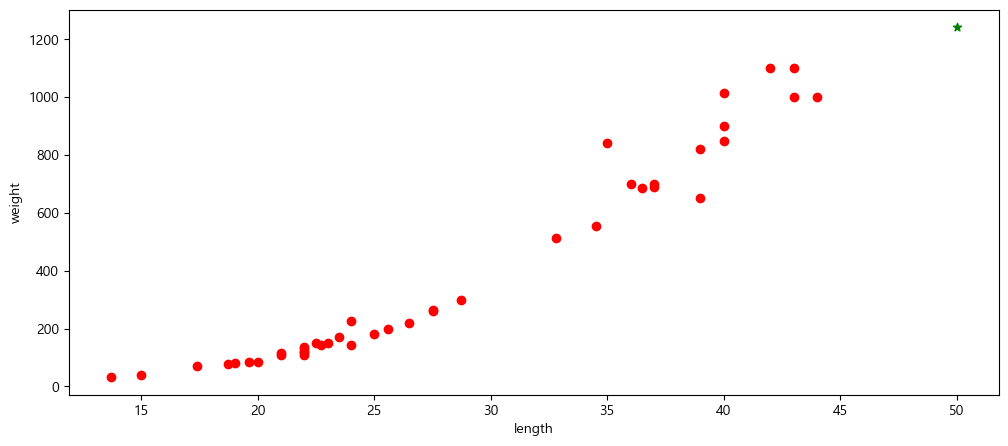

In [10]:
### 훈련 독립변수와 종속변수로 산점도 그래프 그리기 (빨간색)
### 임의값 50과 예측결과로 산점도 그래프 그리기(초록색)

# - 훈련데이터에 대한 산점도
plt.scatter(train_input, train_target, c="red", label="train")

# - 임의값에 대한 산점도
plt.scatter(50, pred_50[0], c="green", label="pred", marker="*")

plt.xlabel("length")
plt.ylabel("weight")
plt.show()

### 훈련 모델이 찾아낸 기울기(가중치)와 y절편을 이용하여 추세선 그리기

In [11]:
### 모델이 찾아낸 기울기(가중치)
coef = lnr.coef_

### 모델이 찾아낸 y절편
intercept = lnr.intercept_

print(coef, intercept)

[39.01714496] -709.0186449535474


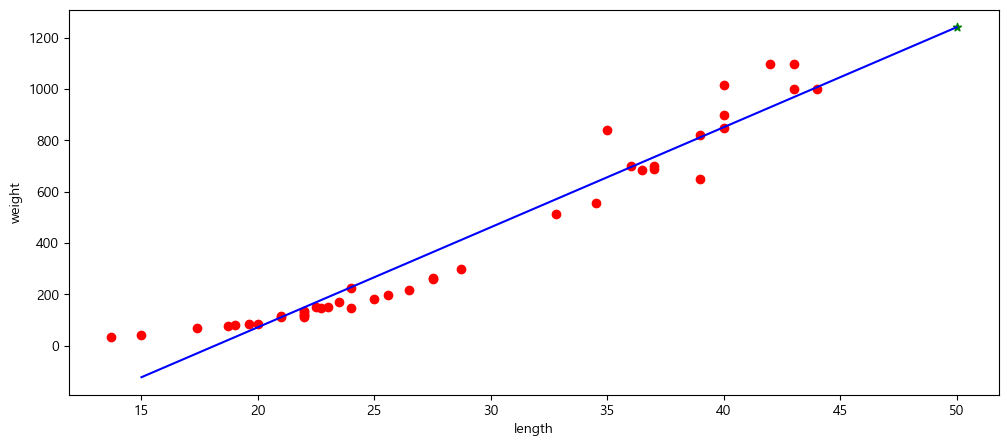

In [12]:

# - 훈련데이터에 대한 산점도
plt.scatter(train_input, train_target, c="red", label="train")

# - 임의값에 대한 산점도
plt.scatter(50, pred_50[0], c="green", label="pred", marker="*")

# - 훈련모델이 찾아낸 기울기와 절편을 이용하여 추세선 그리기(선 그래프 그리기)
# - x축값: [15, 50]
# - y축값: 계산에 의해서 시작y와 끝y 값을 직선의 방정식으로 계산
#        : y = aX + b = coef * 15 + intercept
#        : y = aX + b = coef * 50 + intercept
y1 = coef * 15 + intercept
y2 = coef * 50 + intercept

plt.plot([15, 50], [y1, y2], c="blue", label="Line")

plt.xlabel("length")
plt.ylabel("weight")
plt.show()

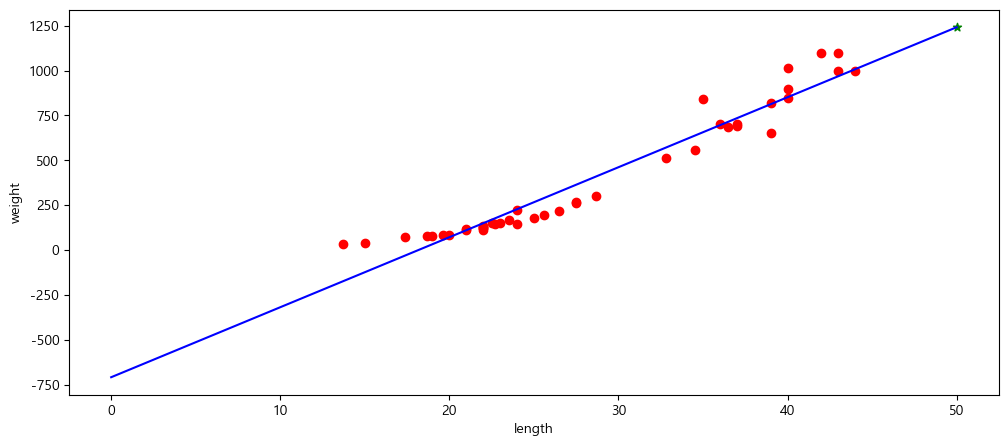

In [13]:

# - 훈련데이터에 대한 산점도
plt.scatter(train_input, train_target, c="red", label="train")

# - 임의값에 대한 산점도
plt.scatter(50, pred_50[0], c="green", label="pred", marker="*")

# - 훈련모델이 찾아낸 기울기와 절편을 이용하여 추세선 그리기(선 그래프 그리기)
# - x축값: [0, 50]
# - y축값: 계산에 의해서 시작y와 끝y 값을 직선의 방정식으로 계산
#        : y = aX + b = coef * 15 + intercept
#        : y = aX + b = coef * 50 + intercept
y1 = coef * 0 + intercept
y2 = coef * 50 + intercept

plt.plot([0, 50], [y1, y2], c="blue", label="Line")

plt.xlabel("length")
plt.ylabel("weight")
plt.show()

In [14]:
### (해석)
# - 추세선에 가까운 데이터(산점)들이 많을 수록 모델 예측력은 좋다고 판단함
# - 추세선에서 떨어진 거리의 평균을 오차평균 이라고 칭합니다.
# - 예측하고자하는 모델의 y절편 값이 음수(-)인 경우에는 예측력이 좋더라도 고민해야 함
#   --> 예측하고자하는 종속변수(y)의 값이 음수(-) 값이 나올 확율이 있다는 의미임
#       (무게는 음수가 될 수 없음)
# - 따라서, 해당 모델로 예측하는데는 부적절하다고 판단됨


### 그래서 어떻게??
# - 훈련데이터의 산점도의 선형 분포를 다시 확인하여
# - 곡선을 띄는 부분이 있는지 확인하여 곡선의 방정식을 사용하도록 유도..


## 다항회귀모델 적용하기(곡선의 방정식 적용)

In [15]:
"""
<다항회귀모델>
 - 다항식(포물선의 방정식)을 사용하는 회귀모델
 - 산점도의 분포 형태가 곡선을 띄는 경우에 사용되는 모델 입니다.
 - 특성이 2개 사용됨 : x^2, x
 - 다항식(y) = ax^2 + bx + c
 - a와 b : 기울기(머신러닝에서는 기울기 = 가중치 = 계수라고 칭합니다.)
 - c : y절편
 - 다항회귀에서는 x값을 제곱한 특성값이 하나더 추가됩니다.(만들어 줘야 합니다.)
"""

'\n<다항회귀모델>\n - 다항식(포물선의 방정식)을 사용하는 회귀모델\n - 산점도의 분포 형태가 곡선을 띄는 경우에 사용되는 모델 입니다.\n - 특성이 2개 사용됨 : x^2, x\n - 다항식(y) = ax^2 + bx + c\n - a와 b : 기울기(머신러닝에서는 기울기 = 가중치 = 계수라고 칭합니다.)\n - c : y절편\n - 다항회귀에서는 x값을 제곱한 특성값이 하나더 추가됩니다.(만들어 줘야 합니다.)\n'

### 훈련 및 테스트(검증데이터가 있는 경우 포함) 데이터에 대한 특성 추가하기

- 아래는 리스트이기 때문에 DF에서 컬럼 추가한 것과 다름.

In [16]:
### 리스트 구조 : [[1, 2], [3, 4].....]
# - column_stack() : 행열 차원에서 열 추가하는 함수(numpy 제공)
train_poly = np.column_stack((train_input**2, train_input))
test_poly = np.column_stack((test_input**2, test_input))
print(train_poly)

[[ 384.16   19.6 ]
 [ 484.     22.  ]
 [ 349.69   18.7 ]
 [ 302.76   17.4 ]
 [1296.     36.  ]
 [ 625.     25.  ]
 [1600.     40.  ]
 [1521.     39.  ]
 [1849.     43.  ]
 [ 484.     22.  ]
 [ 400.     20.  ]
 [ 484.     22.  ]
 [ 576.     24.  ]
 [ 756.25   27.5 ]
 [1849.     43.  ]
 [1600.     40.  ]
 [ 576.     24.  ]
 [ 441.     21.  ]
 [ 756.25   27.5 ]
 [1600.     40.  ]
 [1075.84   32.8 ]
 [ 702.25   26.5 ]
 [1332.25   36.5 ]
 [ 187.69   13.7 ]
 [ 515.29   22.7 ]
 [ 225.     15.  ]
 [1369.     37.  ]
 [1225.     35.  ]
 [ 823.69   28.7 ]
 [ 552.25   23.5 ]
 [1521.     39.  ]
 [ 441.     21.  ]
 [ 529.     23.  ]
 [ 484.     22.  ]
 [1936.     44.  ]
 [ 506.25   22.5 ]
 [ 361.     19.  ]
 [1369.     37.  ]
 [ 484.     22.  ]
 [ 655.36   25.6 ]
 [1764.     42.  ]
 [1190.25   34.5 ]]


### 다항회귀모델 훈련(학습)하기

In [17]:
### 모델 생성부터 임의의값 50길이로 예측까지 해주세요..

# 1. 클래스 생성
lr = LinearRegression()
lr

# 2. 훈련
lr.fit(train_poly, train_target)

# 3. 정확도 측정 훈련 및 테스트 둘 다
trainp_score = lr.score(train_poly, train_target)
testp_score = lr.score(test_poly, test_target)
print(trainp_score, testp_score, trainp_score - testp_score)
# 과소적합 발견됨. trainp_score - testp_score = 음수

# 4. 예측하기 훈련 및 테스트 둘 다
pred_trainp = lr.predict(train_poly)
pred_testp = lr.predict(test_poly)
print(pred_trainp, pred_testp)
# 5. 오차 검증
#mae
print(mean_absolute_error(train_target, pred_trainp))
print(mean_absolute_error(test_target, pred_testp))
#mse
print(mean_squared_error(train_target, pred_trainp))
print(mean_squared_error(test_target, pred_testp))

# 6. 임의의값 50길이로 예측
pred_50p = lr.predict([[50**2, 50]])
print(f"길이 50을 예측한 결과는 {pred_50p}")

### 특성 2개를 사용한 선형회귀모델의 경우 훈련정확도가 테스트정확도보다 낮게 나오는
#    -> 과소적합이 발생하고 있음. 따라서, 예측모델로 사용하기에는 부적합함
#    -> 튜닝 속성이 없기에 다른 방법을 찾아야 함(다중회귀모델을 사용 -> 특성 3개 이상)

0.9706807451768623 0.9775935108325122 -0.006912765655649911
[  83.18070434  132.71260219   67.61880901   48.04150559  654.5393253
  211.05965467  876.66458663  818.09027497 1064.55950693  132.71260219
   90.62455496  132.71260219  182.91530629  290.29593158 1064.55950693
  876.66458663  182.91530629  110.65424646  290.29593158  876.66458663
  500.20932803  257.07992265  680.52990177   11.08663218  149.3605064
   20.90606071  707.0276443   604.07967051  332.83297906  169.60388118
  818.09027497  110.65424646  156.79962213  132.71260219 1131.24847547
  144.50252913   72.62352767  707.0276443   132.71260219  228.92002253
  999.89920261  579.6105922 ] [   6.5349146    56.6511646   290.29593158  117.05874344  144.50252913
  876.66458663  382.21135986  199.55847561  818.09027497  110.65424646
 1097.65040817   33.01314491  307.66468513  283.49043666]
34.996086279552344
37.76606283367664
3617.9917403639624
2248.9974694392704
길이 50을 예측한 결과는 [1573.98423528]


In [18]:
### 훈련 모델에서 찾아낸 기울기와 절편 추출하기
coef = lr.coef_
intercept = lr.intercept_

print(coef, intercept)

[  1.01433211 -21.55792498] 116.0502107827827


In [19]:
### 추세선에 사용할 X축 범위 리스트 값 정의
# - arange(0, 51) 0부터 51보다 1작을 때까지 순차적인 값을 만들어냄.
x_data = np.arange(0, 51)
print(x_data)


### 추세선에 사용할 y축 범위 리스트 값 정의
y_data = coef[0] * x_data**2 + coef[1] * x_data + intercept
print(y_data)

[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50]
[ 116.05021078   95.50661791   76.99168926   60.50542483   46.04782462
   33.61888862   23.21861685   14.84700929    8.50406595    4.18978683
    1.90417193    1.64722125    3.41893479    7.21931254   13.04835452
   20.90606071   30.79243112   42.70746575   56.6511646    72.62352767
   90.62455496  110.65424646  132.71260219  156.79962213  182.91530629
  211.05965467  241.23266727  273.43434409  307.66468513  343.92369038
  382.21135986  422.52769355  464.87269146  509.24635359  555.64867994
  604.07967051  654.5393253   707.0276443   761.54462753  818.09027497
  876.66458663  937.26756251  999.89920261 1064.55950693 1131.24847547
 1199.96610822 1270.7124052  1343.48736639 1418.2909918  1495.12328143
 1573.98423528]


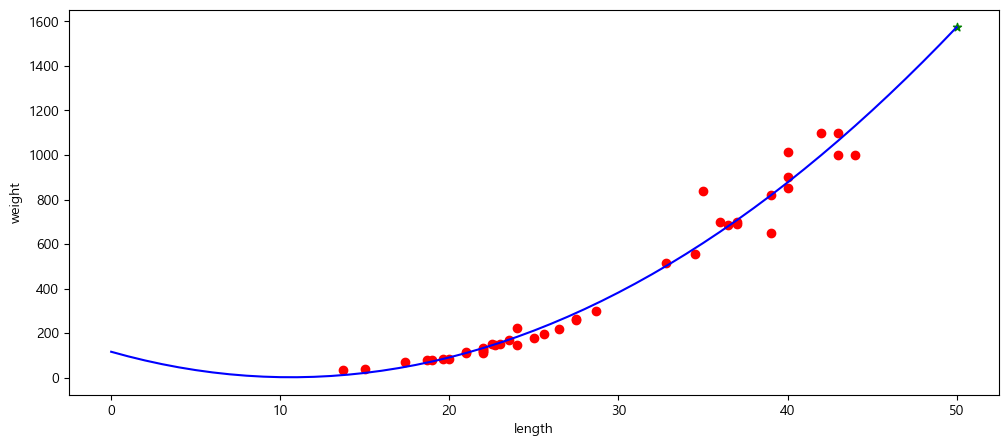

In [20]:

# - 훈련데이터에 대한 산점도
plt.scatter(train_input, train_target, c="red", label="train")

# - 임의값에 대한 산점도
plt.scatter(50, pred_50p[0], c="green", label="pred", marker="*")

# - 훈련모델이 찾아낸 기울기와 절편을 이용하여 추세선 그리기(선 그래프 그리기)
plt.plot(x_data, y_data, c="blue", label="Line")

plt.xlabel("length")
plt.ylabel("weight")
plt.show()

In [21]:
## 특성 2개를 사용한 선형회귀모델 추세선 그리기

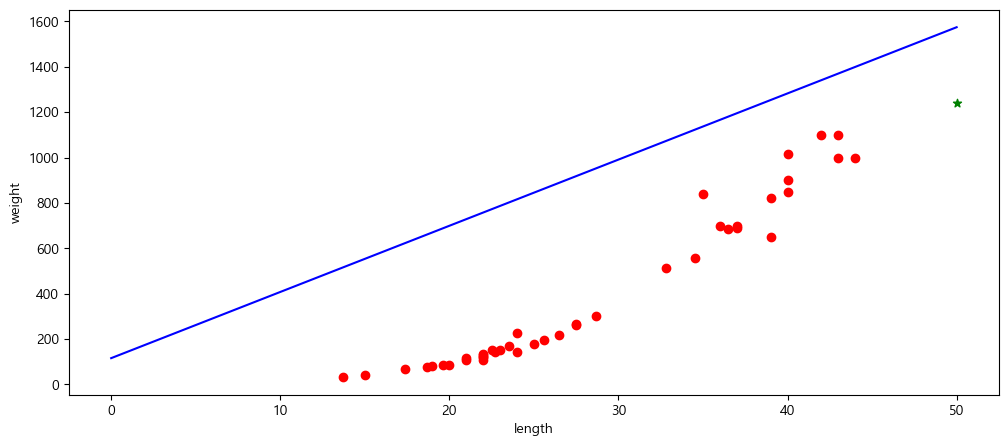

In [22]:

# - 훈련데이터에 대한 산점도
plt.scatter(train_input, train_target, c="red", label="train")

# - 임의값에 대한 산점도
plt.scatter(50, pred_50[0], c="green", label="pred", marker="*")

# - 훈련모델이 찾아낸 기울기와 절편을 이용하여 추세선 그리기(선 그래프 그리기)
# - x축값: [0, 50]
# - y축값: 계산에 의해서 시작y와 끝y 값을 직선의 방정식으로 계산
#        : y = aX**2 + bX + c = coef[0] * 0**2 + coef[1]* 0 + intercept
#        : y = aX**2 + bX + c = coef[0] * 50**2 + coef[1]* 50 + intercept
y1 =  coef[0] * 0**2 + coef[1]* 0 + intercept
y2 = coef[0] * 50**2 + coef[1]* 50 + intercept

plt.plot([0, 50], [y1, y2], c="blue", label="Line")

plt.xlabel("length")
plt.ylabel("weight")
plt.show()

In [23]:
### (해석)
# - 훈련 및 테스트의 정확도(결정계수)의 결과로 볼 때
#   미세한 과소적합이 발생한 모델로, 사용은 가능하나 해소하는 것이 좋음


# <선형회귀에서 과소적합 해소 방법>
# - 하이퍼파라메터 튜닝(선형회귀에서는 튜닝 대상 모델이 아님, 변수 없음)
# - 복잡도(x값=특성=컬럼=퓨처) 늘리기
# - 다른모델 사용
# - 데이터양 늘리기


# - 복잡도 늘리기
#  --> 다중회귀모델은 복잡도를 높인 모델임
#  --> 빅데이터 공학의 개념이 적용된 모델로 "특성공학"이라는 개념을 적용하여
#      특성을 늘려서 과적합을 해소할 수 있음(무조건 적이지는 않음)